# Pricing Data Scientist Assessment — Demand Forecasting

**Goal / هدف:** forecast each product's **total sales over the next 30 days**
and build a defensible training / validation / evaluation pipeline.

This notebook is intentionally light and runs on a **subset of products** so it
finishes in a few minutes on a CPU-only laptop (no GPU), as the task allows.
All heavy logic lives in the `src/` modules and is imported here, so the
notebook stays readable and the code is reused by the tests and scripts.

> **Note (EN):** The `date` column is a **Jalali (Persian) calendar** string
> (`YYYYMMDD`); we convert it to Gregorian for day arithmetic and keep the
> Jalali month for seasonality.
>
> **نکته (FA):** ستون `date` به‌صورت تاریخ **شمسی** (`YYYYMMDD`) است؛ آن را به
> میلادی تبدیل می‌کنیم و ماه شمسی را برای فصلی‌بودن نگه می‌داریم.

In [1]:
# Make the src/ package importable and configure plotting.
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 120)

MAX_PRODUCTS = 300  # subset for speed; set to None to use all 1,235 products.

## 1. Load data / بارگذاری داده

In [2]:
from data_io import load_raw
from run_experiment import subset_products

raw = subset_products(load_raw(), MAX_PRODUCTS)
print("rows:", f"{len(raw):,}", "| products:", raw['product_id'].nunique())
raw.head()

rows: 219,030 | products: 300


,date,product_id,brand_id,Level1,Level2,Level3,Level4,Level5,sale_qty,stock_qty,num_stores_with_stock,discount_pct,price,jyear,jmonth,jday
7320,2024-09-21,P_0011,B_163,L1_003,L2_012,L3_024,L4_036,L5_138,237.98,4098.13,113.0,26.4,440169.0,1403,6,31
7321,2024-09-22,P_0011,B_163,L1_003,L2_012,L3_024,L4_036,L5_138,198.32,3612.25,107.0,26.1,441220.0,1403,7,1
7322,2024-09-23,P_0011,B_163,L1_003,L2_012,L3_024,L4_036,L5_138,243.65,3657.58,107.0,26.1,440194.0,1403,7,2
7323,2024-09-24,P_0011,B_163,L1_003,L2_012,L3_024,L4_036,L5_138,179.90,3354.43,103.0,25.8,439135.0,1403,7,3
7324,2024-09-25,P_0011,B_163,L1_003,L2_012,L3_024,L4_036,L5_138,208.24,3202.86,101.0,25.7,441220.0,1403,7,4


## 2. Exploratory data analysis (EDA) / تحلیل اکتشافی

We look at the panel structure, the target distribution, history length per
product, and how price/discount relate to sales.

In [3]:
from config import PRODUCT_COL, DATE_COL, TARGET_COL

n_products = raw[PRODUCT_COL].nunique()
span_days = (raw[DATE_COL].max() - raw[DATE_COL].min()).days + 1
print(f"Date range: {raw[DATE_COL].min().date()} -> {raw[DATE_COL].max().date()} ({span_days} days)")
print(f"Products: {n_products}  |  Panel density: {len(raw) / (n_products * span_days):.1%}")
print(f"Zero-sale share among recorded rows: {(raw[TARGET_COL] == 0).mean():.1%}")
raw[[TARGET_COL, 'price', 'discount_pct', 'stock_qty', 'num_stores_with_stock']].describe().T

Date range: 2024-09-21 -> 2026-09-22 (732 days)
Products: 300  |  Panel density: 99.7%
Zero-sale share among recorded rows: 2.4%


,count,mean,std,min,25%,50%,75%,max
sale_qty,219030.0,6.064582e+02,1.183475e+03,0.00,81.0000,233.700,6.312675e+02,94577.62
price,219030.0,1.564790e+06,1.713906e+06,0.00,481386.7500,952214.500,2.044234e+06,14768362.00
discount_pct,219030.0,9.302872e+00,7.796302e+00,0.00,2.6000,8.200,1.400000e+01,64.70
stock_qty,219030.0,1.483390e+04,2.353238e+04,0.64,3385.9725,8135.195,1.692457e+04,650221.32
num_stores_with_stock,219030.0,2.100844e+02,9.776348e+01,0.00,142.0000,238.000,2.820000e+02,386.00


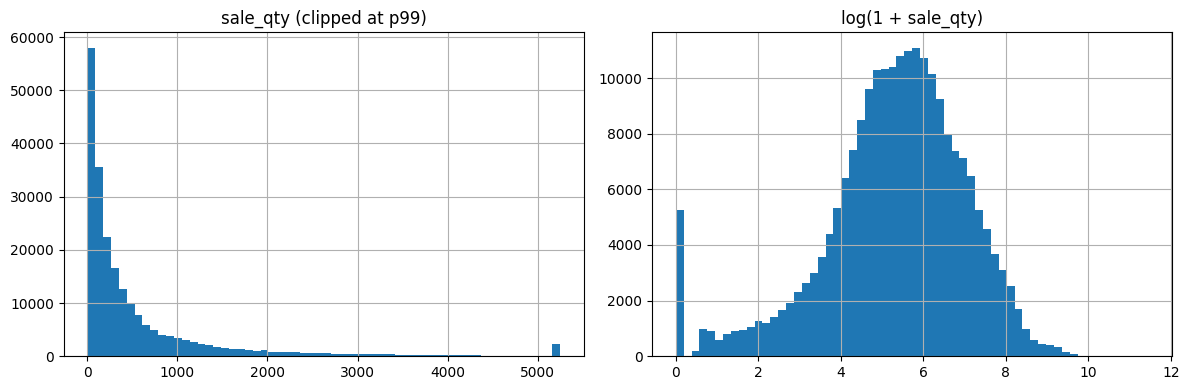

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
raw[TARGET_COL].clip(upper=raw[TARGET_COL].quantile(0.99)).hist(bins=60, ax=axes[0])
axes[0].set_title("sale_qty (clipped at p99)")
np.log1p(raw[TARGET_COL]).hist(bins=60, ax=axes[1])
axes[1].set_title("log(1 + sale_qty)")
plt.tight_layout(); plt.show()

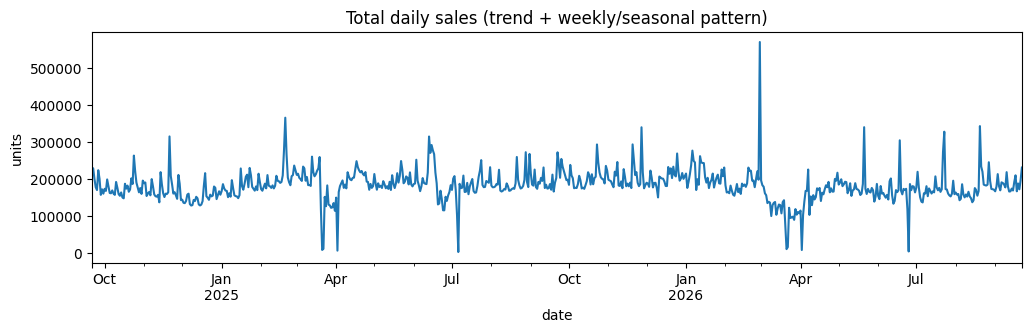

In [5]:
daily_total = raw.groupby(DATE_COL)[TARGET_COL].sum()
daily_total.plot(figsize=(12, 3), title="Total daily sales (trend + weekly/seasonal pattern)")
plt.ylabel("units"); plt.show()

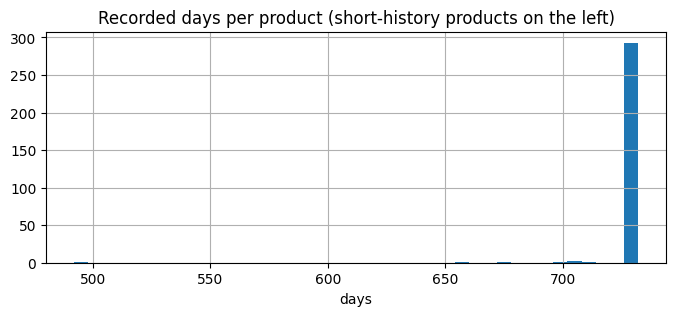

In [6]:
rows_per_product = raw.groupby(PRODUCT_COL).size()
rows_per_product.hist(bins=40, figsize=(8, 3))
plt.title("Recorded days per product (short-history products on the left)")
plt.xlabel("days"); plt.show()

## 3. Preprocessing / پیش‌پردازش

Key decisions (details in the Technical Note):
- **Missing records** are reindexed to a daily calendar *within each product's
  own lifespan* and flagged (`is_imputed_day`) — not blindly treated as zeros.
- **Zero sales vs. zero stock** are separated: a zero sale while out of stock is
  *censored* (`is_stockout`), not true zero demand (`is_true_zero_demand`).
- **Spikes** are **winsorized** (robust MAD rule), not deleted — promotions are
  real demand we want to keep.

In [7]:
from preprocessing import preprocess
from config import BRAND_COL, HIERARCHY_COLS

daily = preprocess(raw, static_cols=[BRAND_COL, *HIERARCHY_COLS])
flag_cols = ['is_imputed_day', 'is_stockout', 'is_true_zero_demand', 'is_spike_capped']
print("Flag rates:")
print(daily[flag_cols].mean().round(4))
daily[[PRODUCT_COL, DATE_COL, TARGET_COL, 'sale_qty_raw', *flag_cols]].head()

Flag rates:
is_imputed_day         0.0024
is_stockout            0.0024
is_true_zero_demand    0.0239
is_spike_capped        0.0094
dtype: float64


,product_id,date,sale_qty,sale_qty_raw,is_imputed_day,is_stockout,is_true_zero_demand,is_spike_capped
0,P_0011,2024-09-21,237.98,237.98,0,0,0,0
1,P_0011,2024-09-22,198.32,198.32,0,0,0,0
2,P_0011,2024-09-23,243.65,243.65,0,0,0,0
3,P_0011,2024-09-24,179.90,179.90,0,0,0,0
4,P_0011,2024-09-25,208.24,208.24,0,0,0,0


## 4. Feature engineering / مهندسی ویژگی

Three families: **calendar** (future-known), **own-history** (lags/rolling,
intermittency), and **competitive** features that describe each product versus
its substitutes in the same `Level4` group.

In [8]:
from features import add_all_features, COMPETITIVE_FEATURE_NAMES

daily = add_all_features(daily)
print("Competitive features:", COMPETITIVE_FEATURE_NAMES)
daily[[PRODUCT_COL, DATE_COL, *COMPETITIVE_FEATURE_NAMES]].dropna().head()

Competitive features: ['price_rank_in_group', 'relative_discount', 'price_gap_to_cheapest', 'relative_store_coverage', 'sales_share_in_group', 'group_sales_momentum']


,product_id,date,price_rank_in_group,relative_discount,price_gap_to_cheapest,relative_store_coverage,sales_share_in_group,group_sales_momentum
29,P_0011,2024-10-20,0.333333,13.191667,380675.0,0.219262,0.014547,-0.398681
30,P_0011,2024-10-21,0.333333,12.691667,380675.0,0.218513,0.013886,-0.344931
31,P_0011,2024-10-22,0.333333,16.391667,380687.0,0.213636,0.012793,-0.284241
32,P_0011,2024-10-23,0.333333,15.708333,380707.0,0.208538,0.011884,-0.217644
33,P_0011,2024-10-24,0.333333,12.108333,380687.0,0.199245,0.010919,-0.147564


## 5. Build direct-forecast samples / ساخت نمونه‌های آموزش

We frame the task as a **direct** forecast of the 30-day sum: one row per
(product, origin) with features known at the origin and the realized 30-day
forward sum as the label. Training origins are weekly (dense); validation
origins are spaced by the horizon so their windows do not overlap.

In [9]:
from run_experiment import select_feature_columns
from samples import build_samples, make_origin_grid, make_validation_origins

feature_cols = select_feature_columns(daily)
train_origins = make_origin_grid(daily)
valid_origins = make_validation_origins(daily, n_folds=3)
all_origins = sorted(set(train_origins) | set(valid_origins))
samples = build_samples(daily, all_origins, feature_cols=feature_cols)
print(f"samples: {len(samples):,} | features: {len(feature_cols)} | validation origins: {[d.date() for d in valid_origins]}")

samples: 27,000 | features: 40 | validation origins: [datetime.date(2026, 6, 24), datetime.date(2026, 7, 24), datetime.date(2026, 8, 23)]


## 6. Modeling experiment: baseline vs. LightGBM / آزمایش مدل

We compare a **recent-average baseline** with **LightGBM** (Tweedie objective,
CPU-friendly) under the **same rolling-origin backtest**, and measure the value
added by the competitive features by training LightGBM with and without them.

In [10]:
from evaluation import rolling_origin_backtest
from models import RecentAverageBaseline, LightGBMForecaster

without_comp = [c for c in feature_cols if c not in COMPETITIVE_FEATURE_NAMES]

baseline = rolling_origin_backtest(lambda: RecentAverageBaseline(), samples, feature_cols, valid_origins)
lgbm_plain = rolling_origin_backtest(LightGBMForecaster, samples, without_comp, valid_origins)
lgbm_full = rolling_origin_backtest(LightGBMForecaster, samples, feature_cols, valid_origins)

report = pd.DataFrame({
    "Baseline": baseline.aggregate,
    "LightGBM (no competitive)": lgbm_plain.aggregate,
    "LightGBM (full)": lgbm_full.aggregate,
}).T
report.round(3)

,WMAPE,MAE,RMSE,Bias
Baseline,0.204,3587.758,8804.614,-826.381
LightGBM (no competitive),0.191,3359.487,8860.898,-774.091
LightGBM (full),0.178,3128.256,7952.094,-755.197


In [11]:
# Per-origin WMAPE shows stability across folds.
baseline.per_origin.assign(model="baseline")[['origin', 'WMAPE', 'MAE']]

,origin,WMAPE,MAE
0,2026-06-24,0.244829,4227.435728
1,2026-07-24,0.165468,2807.963074
2,2026-08-23,0.201297,3727.875976


## 7. Feature importance / اهمیت ویژگی‌ها

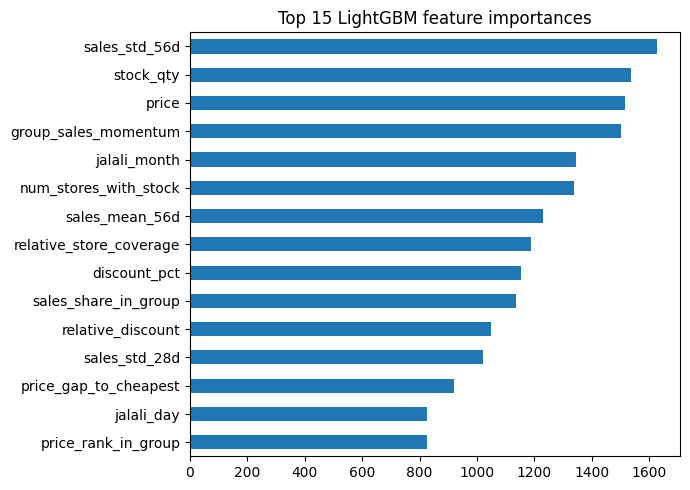

sales_std_56d              1626
stock_qty                  1536
price                      1517
group_sales_momentum       1502
jalali_month               1345
num_stores_with_stock      1338
sales_mean_56d             1231
relative_store_coverage    1188
discount_pct               1155
sales_share_in_group       1135
relative_discount          1048
sales_std_28d              1021
price_gap_to_cheapest       921
jalali_day                  827
price_rank_in_group         825
dtype: int32

In [12]:
model = LightGBMForecaster().fit(samples[feature_cols], samples['target_30d_sum'])
importance = model.feature_importance.head(15)
importance.iloc[::-1].plot.barh(figsize=(7, 5), title="Top 15 LightGBM feature importances")
plt.tight_layout(); plt.show()
importance

## 8. Conclusions / جمع‌بندی

- **LightGBM beats the baseline** on WMAPE and MAE under an identical,
  leakage-safe, time-based backtest.
- **Competitive features add value**: adding them lowers error and several of
  them rank highly in feature importance (e.g. group momentum, sales share).
- On limited compute we trained on a product subset; the same pipeline scales to
  all products by setting `MAX_PRODUCTS = None`.

See `docs/TECHNICAL_NOTE_EN.md` / `docs/TECHNICAL_NOTE_FA.md` for the full
reasoning and `docs/workflow_diagram.*` for the workflow diagram.